# 03 – Exploratory Analysis & Feature Selection
**Owner:** Jinash  
**Goal:** Explore relationships with winning, measure home-court advantage, and apply feature selection methods to decide which game statistics go into modeling (Notebook 4).

**Input:** `data/processed/games_processed.csv` from Notebook 2. **Output:** the final feature set (last section) and figures in `reports/figures/`.

## Summary of findings

- **Home-court advantage is real and persistent.** Home teams win 60.8% of regular-season games from 2000 to 2025 (95% CI 60.3% to 61.3%). All 26 seasons are above 50%, ranging from 54.5% (2025) to 66.5% (2019).
- **Usable game statistics only exist for 2000–2015.** In 2016–2025 `FT_PCT_diff` is a constant zero and `FG_PCT_diff` has almost no link to winning, so the statistics analysis uses the 16,816 games from 2000–2015 that have all six statistics.
- **Field-goal % difference is the strongest statistic** on every method (correlation 0.62). On its own it classifies 79.6% of games correctly, against 59.7% for always picking the home team.
- **Final feature set (5):** FG%, turnovers, rebounds, 3P% and FT% differences. Assists are dropped: they are strongly related to winning on their own (r = 0.48) but add almost nothing once the other statistics are in the model.
- **These are post-game statistics.** They explain completed games; they do not forecast a game before tip-off.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

TARGET = "HOME_TEAM_WINS"
NICE = {
    "FG_PCT_diff": "FG% diff",
    "FT_PCT_diff": "FT% diff",
    "FG3_PCT_diff": "3P% diff",
    "AST_diff": "Assists diff",
    "REB_diff": "Rebounds diff",
    "TOV_diff": "Turnovers diff",
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## Load the processed data from Notebook 2

In [2]:
df = pd.read_csv(PROCESSED / "games_processed.csv")
ALL_FEATURES = [c for c in df.columns if c.endswith("_diff")]

print("Shape:", df.shape)
print("Seasons:", df["season"].min(), "to", df["season"].max(), f"({df['season'].nunique()} seasons)")
print("Unique game_id:", df["game_id"].is_unique)
print("Target values:", sorted(int(v) for v in df[TARGET].unique()))
print(f"Home win rate: {df[TARGET].mean():.1%}")
print("Features:", ALL_FEATURES)

Shape: (31230, 12)
Seasons: 2000 to 2025 (26 seasons)
Unique game_id: True
Target values: [0, 1]
Home win rate: 60.8%
Features: ['FG_PCT_diff', 'FT_PCT_diff', 'FG3_PCT_diff', 'AST_diff', 'REB_diff', 'TOV_diff']


## Data check: are the statistics usable?

Notebook 2 reports that rebounds, assists, 3P% and turnovers are blank for 2016–2025 and keeps FG% and FT% as the two features that still have values in those seasons. The heatmap shows availability by season. Before relying on FG% and FT% for 2016–2025, the next two checks test whether those values are real.

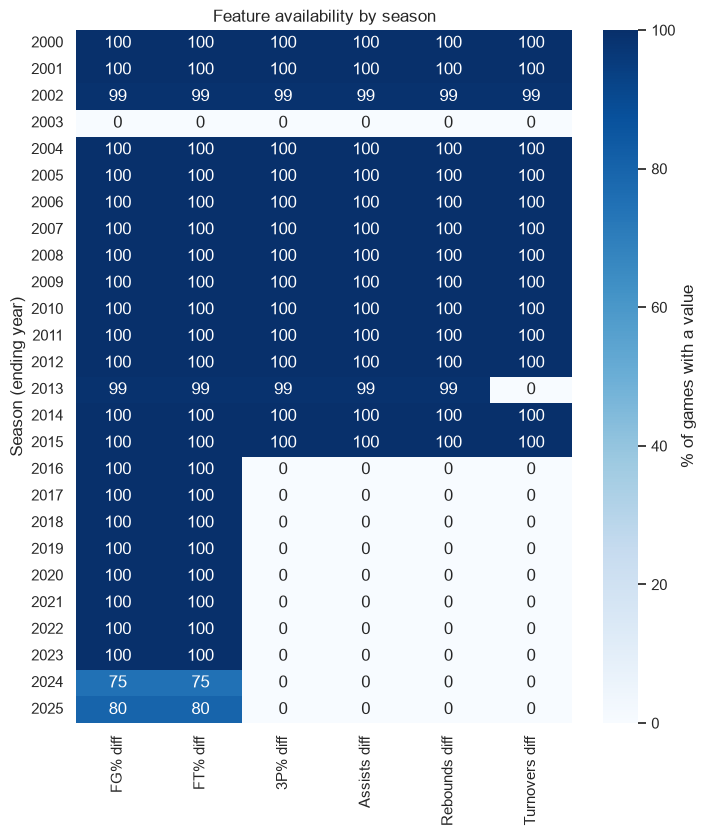

,games_with_value,pct_of_games
FG_PCT_diff,29453,94.3
FT_PCT_diff,29452,94.3
FG3_PCT_diff,18033,57.7
AST_diff,18033,57.7
REB_diff,18033,57.7
TOV_diff,16816,53.8


In [3]:
availability = (
    df.groupby("season")[ALL_FEATURES]
    .apply(lambda g: g.notna().mean() * 100)
    .rename(columns=NICE)
)

plt.figure(figsize=(8, 9))
sns.heatmap(availability, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            cbar_kws={"label": "% of games with a value"})
plt.title("Feature availability by season")
plt.ylabel("Season (ending year)")
plt.savefig(FIGURES / "feature_availability_by_season.png", bbox_inches="tight", dpi=150)
plt.show()

pd.DataFrame({
    "games_with_value": df[ALL_FEATURES].notna().sum(),
    "pct_of_games": (df[ALL_FEATURES].notna().mean() * 100).round(1),
})

### Free-throw %

Raw `home_ft_pct` and `away_ft_pct` values (regular season, 2000–2025), split by period:

In [4]:
raw = pd.read_csv(RAW / "public.dim_games.csv", low_memory=False,
                  usecols=["season", "season_type", "home_ft_pct", "away_ft_pct"])
raw = raw[raw["season"].between(2000, 2025) & (raw["season_type"] == "Regular Season")]
ft = raw.melt(id_vars="season", value_vars=["home_ft_pct", "away_ft_pct"]).dropna(subset=["value"])
ft["period"] = np.where(ft["season"] <= 2015, "2000-2015", "2016-2025")

ft_check = ft.groupby("period")["value"].agg(
    team_game_values="size",
    share_exactly_zero=lambda v: (v == 0).mean(),
    mean="mean",
    distinct_values="nunique",
)
ft_check.round(3)

,team_game_values,share_exactly_zero,mean,distinct_values
period,,,,
2000-2015,36066,0.0,0.755,376
2016-2025,23240,1.0,0.000,1


### Field-goal %

The team that shoots better usually wins, so the FG% difference should be strongly related to the result in every season. The left chart tracks that correlation by season. The right chart shows how often `FT_PCT_diff` is exactly zero.

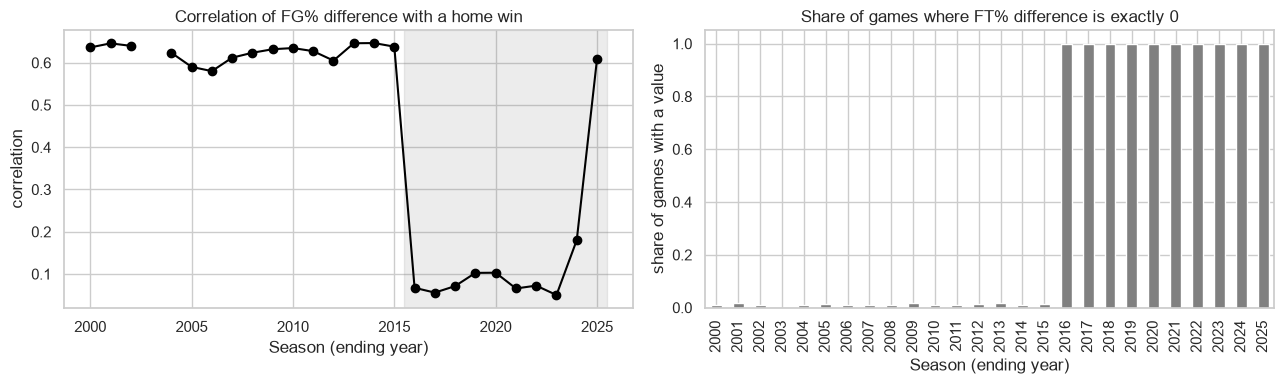

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
games_with_FG_diff,1189.000,1189.000,1189.000,0.0,1189.000,1230.000,1230.000,1230.000,1230.000,1230.000,...,1230.000,1230.000,1230.000,1230.000,1059.000,1080.000,1230.000,1230.00,919.00,982.000
corr_FG_diff_with_win,0.636,0.646,0.640,NaN,0.624,0.590,0.580,0.612,0.624,0.632,...,0.067,0.056,0.071,0.103,0.103,0.066,0.072,0.05,0.18,0.609
share_FT_diff_exactly_zero,0.010,0.017,0.008,NaN,0.012,0.012,0.011,0.010,0.009,0.017,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.00,1.00,1.000


In [5]:
per_season = pd.DataFrame({
    "games_with_FG_diff": df.groupby("season")["FG_PCT_diff"].count(),
    "corr_FG_diff_with_win": pd.Series({s: g["FG_PCT_diff"].corr(g[TARGET]) for s, g in df.groupby("season")}),
    "share_FT_diff_exactly_zero": df.groupby("season")["FT_PCT_diff"].apply(lambda x: (x.dropna() == 0).mean()),
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_season["corr_FG_diff_with_win"].plot(marker="o", color="black", ax=axes[0])
axes[0].axvspan(2015.5, 2025.5, color="gray", alpha=0.15)
axes[0].set(title="Correlation of FG% difference with a home win", xlabel="Season (ending year)",
            ylabel="correlation")
per_season["share_FT_diff_exactly_zero"].plot(kind="bar", color="gray", ax=axes[1])
axes[1].set(title="Share of games where FT% difference is exactly 0", xlabel="Season (ending year)",
            ylabel="share of games with a value")
plt.tight_layout()
plt.savefig(FIGURES / "data_quality_2016_2025.png", bbox_inches="tight", dpi=150)
plt.show()

per_season.round(3).T

### Result: the 2016–2025 statistics cannot be used

- **Free-throw %:** every recorded value in 2016–2025 is exactly 0 (a single distinct value, against 376 in 2000–2015). The home-minus-away difference is therefore 0 in all of those games. These are placeholders, not measurements, and Notebook 2 carried them through as real zeros.
- **Field-goal %:** the FG% difference has a correlation of about 0.58 to 0.65 with winning in every season from 2000 to 2015, but only 0.05 to 0.10 in 2016–2023 and 0.18 in 2024. It returns to 0.61 in 2025. A shooting statistic should not become unrelated to the result for eight straight seasons, so the 2016–2024 FG% values look unreliable. The 2025 values look consistent with earlier years, but no other statistic is available for that season.
- **Rebounds, assists, 3P% and turnovers** are completely blank in these seasons.

**Decision for this notebook:** all statistic-based analysis uses only games where all six statistics exist, which means 2000–2015 (no 2003, no 2013). Nothing is imputed. The home-court section uses all seasons because it only needs the final score.

**Open issue for the group:** `data/processed/games_processed.csv` still contains these 2016–2025 values. A model that uses `FT_PCT_diff` or `FG_PCT_diff` on those rows would be training on placeholders or unreliable numbers. This should be raised with Tony (Notebook 2); it is not changed here.

## Analysis sample

All statistic-based analysis below uses the **`complete`** sample: games where all six difference features exist.
Nothing is imputed or filled with zero. The home-court section uses all 31,230 games because it only needs the final score.

In [6]:
complete = df.dropna(subset=ALL_FEATURES).copy()
complete["Outcome"] = complete[TARGET].map({1: "Home win", 0: "Home loss"})

# By construction this is exactly the 2000-2015 games that have a recorded box score.
assert complete["season"].max() <= 2015

pd.DataFrame({
    "games": [len(df), len(complete)],
    "seasons": [df["season"].nunique(), complete["season"].nunique()],
    "first_season": [df["season"].min(), complete["season"].min()],
    "last_season": [df["season"].max(), complete["season"].max()],
    "home_win_rate": [df[TARGET].mean(), complete[TARGET].mean()],
}, index=["all games", "complete sample (all 6 features)"]).round(3)

,games,seasons,first_season,last_season,home_win_rate
all games,31230,26,2000,2025,0.608
complete sample (all 6 features),16816,14,2000,2015,0.597


## 1. Home-court advantage by season

Uses all 31,230 regular-season games, since the final score (and so the target) is complete for every game.
Each season's rate has a 95% Wilson confidence interval and a two-sided binomial test against 50% (no home-court advantage).

In [7]:
def wilson_ci(k, n, level=0.95):
    ci = stats.binomtest(int(k), int(n), 0.5).proportion_ci(confidence_level=level, method="wilson")
    return ci.low, ci.high


season_tbl = df.groupby("season")[TARGET].agg(games="size", home_wins="sum")
season_tbl["home_win_rate"] = season_tbl["home_wins"] / season_tbl["games"]
ci = [wilson_ci(k, n) for k, n in zip(season_tbl["home_wins"], season_tbl["games"])]
season_tbl["ci_low"] = [c[0] for c in ci]
season_tbl["ci_high"] = [c[1] for c in ci]
season_tbl["p_vs_50pct"] = [stats.binomtest(int(k), int(n), 0.5).pvalue
                            for k, n in zip(season_tbl["home_wins"], season_tbl["games"])]

k, n = int(df[TARGET].sum()), len(df)
lo, hi = wilson_ci(k, n)
p_all = stats.binomtest(k, n, 0.5).pvalue
print(f"Overall home win rate: {k / n:.1%}  (95% CI {lo:.1%} to {hi:.1%}),  n = {n:,},  p = {p_all:.2e}")
print(f"Seasons above 50% at p < 0.05:          {(season_tbl['p_vs_50pct'] < 0.05).sum()} of {len(season_tbl)}")
print(f"Seasons above 50% at p < 0.05 / {len(season_tbl)}:      {(season_tbl['p_vs_50pct'] < 0.05 / len(season_tbl)).sum()} of {len(season_tbl)}  (Bonferroni)")
print(f"Lowest season:  {season_tbl['home_win_rate'].idxmin()} ({season_tbl['home_win_rate'].min():.1%})")
print(f"Highest season: {season_tbl['home_win_rate'].idxmax()} ({season_tbl['home_win_rate'].max():.1%})")

season_tbl.round(4)

Overall home win rate: 60.8%  (95% CI 60.3% to 61.3%),  n = 31,230,  p = 1.95e-321
Seasons above 50% at p < 0.05:          26 of 26
Seasons above 50% at p < 0.05 / 26:      26 of 26  (Bonferroni)
Lowest season:  2025 (54.5%)
Highest season: 2019 (66.5%)


,games,home_wins,home_win_rate,ci_low,ci_high,p_vs_50pct
season,,,,,,
2000,1189,726,0.6106,0.5826,0.6379,0.0000
2001,1189,711,0.5980,0.5698,0.6255,0.0000
2002,1203,712,0.5919,0.5638,0.6193,0.0000
2003,1189,747,0.6283,0.6004,0.6553,0.0000
2004,1192,733,0.6149,0.5870,0.6421,0.0000
2005,1230,744,0.6049,0.5773,0.6318,0.0000
2006,1230,742,0.6033,0.5756,0.6302,0.0000
2007,1230,727,0.5911,0.5633,0.6182,0.0000
2008,1230,739,0.6008,0.5732,0.6278,0.0000


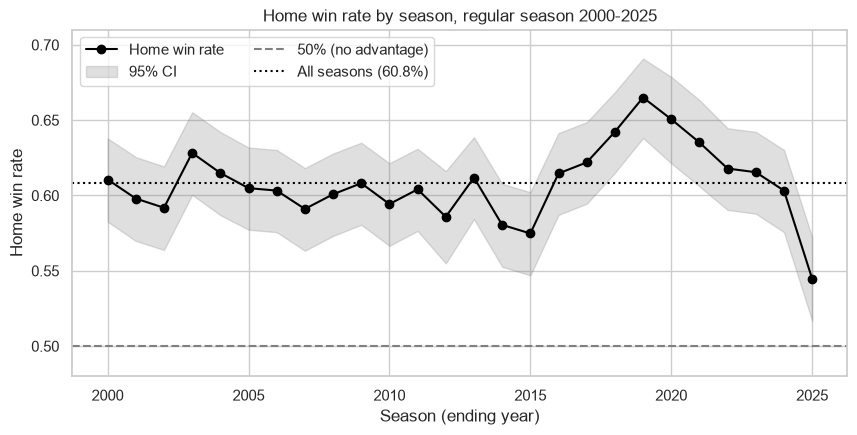

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5))
rate = season_tbl["home_win_rate"]
ax.plot(rate.index, rate, marker="o", color="black", label="Home win rate")
ax.fill_between(rate.index, season_tbl["ci_low"], season_tbl["ci_high"], color="gray", alpha=0.25, label="95% CI")
ax.axhline(0.5, linestyle="--", color="gray", label="50% (no advantage)")
ax.axhline(k / n, linestyle=":", color="black", label=f"All seasons ({k / n:.1%})")
ax.set(title="Home win rate by season, regular season 2000-2025",
       xlabel="Season (ending year)", ylabel="Home win rate")
ax.set_ylim(0.48, 0.71)
ax.legend(loc="upper left", ncol=2)
plt.savefig(FIGURES / "home_win_rate_by_season.png", bbox_inches="tight", dpi=150)
plt.show()

**Reading the chart**

- Home teams win **60.8%** of games (95% CI 60.3% to 61.3%; p < 0.001 against 50%). Every season is individually above 50%, and all 26 still pass a Bonferroni-corrected threshold (0.05 / 26).
- From 2000 to 2013 the rate stays between about 58.6% and 62.8%. It dips to 57.5% in 2015, climbs to a peak of **66.5% in 2019**, stays above 63% through 2021, and falls to **54.5% in 2025**, the lowest season. Its confidence interval (51.7% to 57.2%) is the closest to 50% of any season.
- Each season has roughly 1,000 to 1,230 games, so swings of a few points between neighbouring seasons are within the confidence bands. The seasons whose intervals sit clearly away from the long-run 60.8% are 2018 to 2020 (high) and 2025 (low).

## 2. Distributions by outcome

Each feature is home minus away, so positive means the home team did better (for turnovers, positive means *more* home turnovers).
Plots use the `complete` sample. The table gives the mean for each outcome, the standardised gap (Cohen's d), and the correlation with winning.

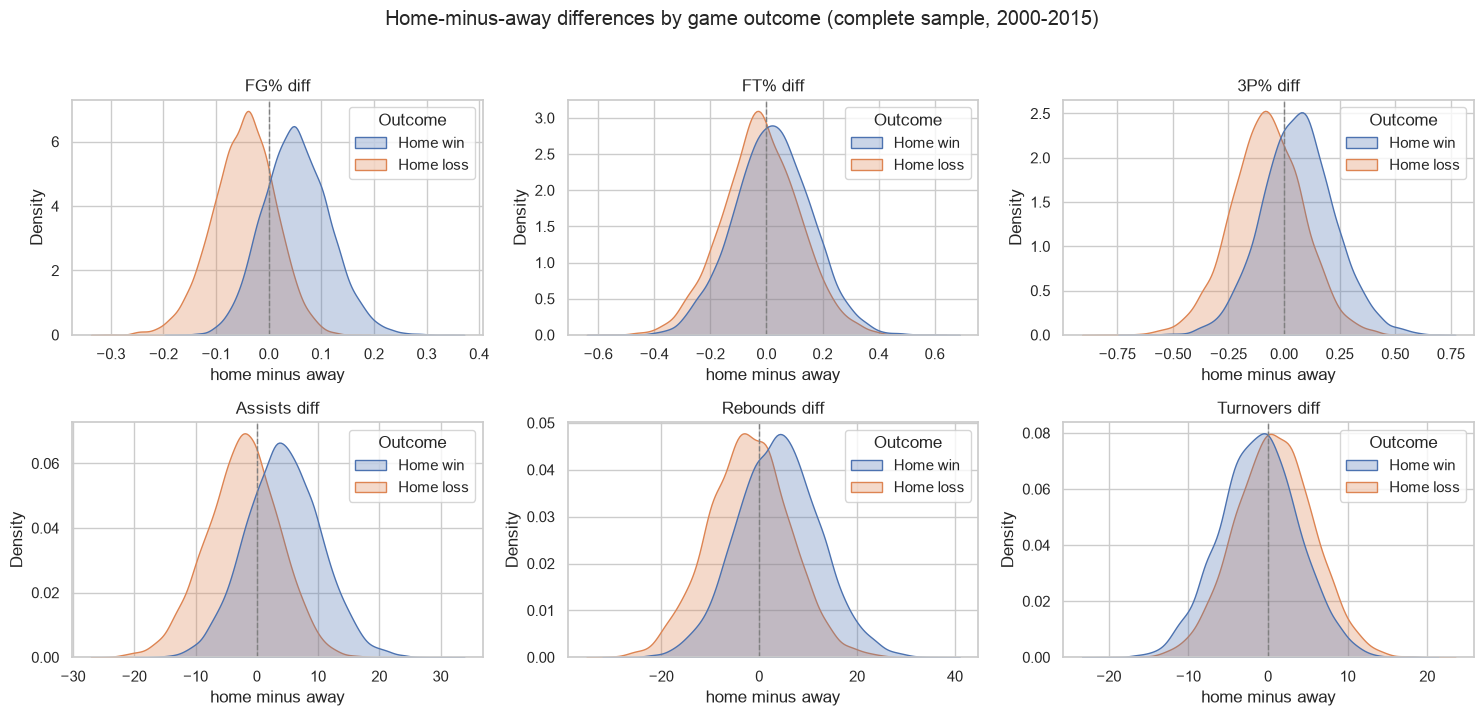

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, f in zip(axes.flat, ALL_FEATURES):
    sns.kdeplot(data=complete, x=f, hue="Outcome", hue_order=["Home win", "Home loss"],
                common_norm=False, fill=True, alpha=0.3, ax=ax)
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(NICE[f])
    ax.set_xlabel("home minus away")
plt.suptitle("Home-minus-away differences by game outcome (complete sample, 2000-2015)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES / "feature_distributions_by_outcome.png", bbox_inches="tight", dpi=150)
plt.show()

In [10]:
def cohens_d(x1, x0):
    n1, n0 = len(x1), len(x0)
    pooled = np.sqrt(((n1 - 1) * x1.var(ddof=1) + (n0 - 1) * x0.var(ddof=1)) / (n1 + n0 - 2))
    return (x1.mean() - x0.mean()) / pooled


rows = []
for f in ALL_FEATURES:
    w, l = complete.loc[complete[TARGET] == 1, f], complete.loc[complete[TARGET] == 0, f]
    rows.append({
        "feature": f,
        "mean_when_home_wins": w.mean(),
        "mean_when_home_loses": l.mean(),
        "cohens_d": cohens_d(w, l),
        "corr_with_win": complete[f].corr(complete[TARGET]),
    })
dist_tbl = pd.DataFrame(rows).set_index("feature").round(3)
dist_tbl.sort_values("cohens_d", key=abs, ascending=False)

,mean_when_home_wins,mean_when_home_loses,cohens_d,corr_with_win
feature,,,,
FG_PCT_diff,0.052,-0.048,1.628,0.624
AST_diff,4.287,-2.348,1.103,0.476
FG3_PCT_diff,0.062,-0.078,0.852,0.386
REB_diff,3.888,-2.156,0.723,0.334
TOV_diff,-1.142,0.761,-0.385,-0.185
FT_PCT_diff,0.020,-0.021,0.299,0.145


**Reading the distributions** (complete sample: 16,816 games, 2000–2015)

- **FG%** separates wins from losses the most. When the home team wins, its FG% is on average 5.2 points above the visitor's; when it loses, 4.8 points below (Cohen's d = 1.63, a very large gap). The two curves barely overlap.
- **Assists** (d = 1.10), **3P%** (d = 0.85) and **rebounds** (d = 0.72) also separate the outcomes clearly, with winners ahead on all three.
- **Turnovers** separate less (d = -0.39). Home winners average 1.1 fewer turnovers than the visitor; home losers average 0.8 more.
- **FT%** is the weakest (d = 0.30); the two curves almost sit on top of each other.
- All six curves are roughly bell-shaped with no obvious data errors, so no games were removed here.

## 3. Feature selection

Four methods plus a drop-one check, all on the `complete` sample so every feature is compared on the same games:

1. Correlation with the target
2. Random forest feature importance (permutation importance on held-out games)
3. Mutual information
4. Logistic regression standardised coefficients
5. Drop-one check (does removing a feature hurt cross-validated performance?)

### Method 1: Correlation with the target

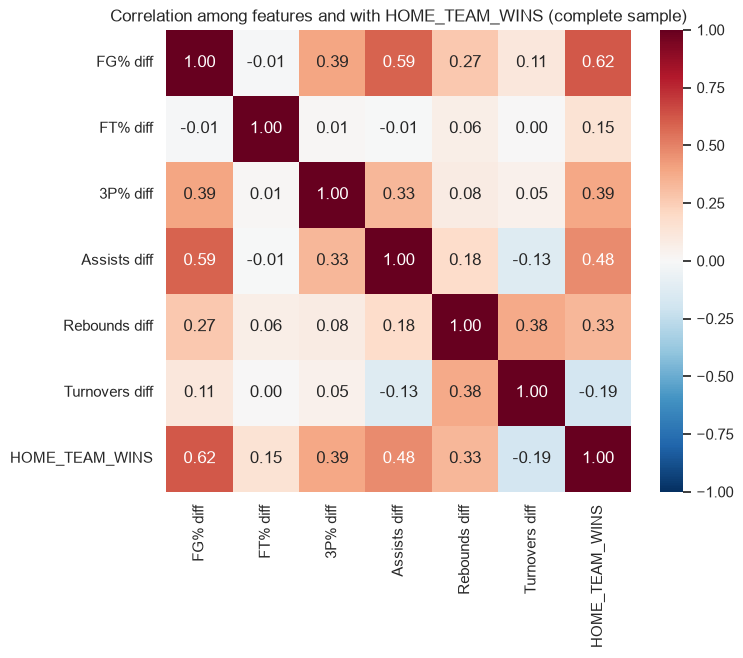

,corr_with_win,p_value
FG_PCT_diff,0.624029,0.000000e+00
AST_diff,0.475956,0.000000e+00
FG3_PCT_diff,0.385659,0.000000e+00
REB_diff,0.334269,0.000000e+00
TOV_diff,-0.185493,4.807531e-130
FT_PCT_diff,0.145246,5.975362e-80


Strongest feature-feature correlations:
FG_PCT_diff   AST_diff        0.592
              FG3_PCT_diff    0.391
REB_diff      TOV_diff        0.377
FG3_PCT_diff  AST_diff        0.333
FG_PCT_diff   REB_diff        0.268
dtype: float64


In [11]:
corr = complete[ALL_FEATURES + [TARGET]].corr()

plt.figure(figsize=(7.5, 6))
sns.heatmap(corr.rename(index=NICE, columns=NICE), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation among features and with HOME_TEAM_WINS (complete sample)")
plt.savefig(FIGURES / "feature_correlation_heatmap.png", bbox_inches="tight", dpi=150)
plt.show()

corr_target = corr[TARGET].drop(TARGET)
pvals = {f: stats.pearsonr(complete[f], complete[TARGET])[1] for f in ALL_FEATURES}
corr_tbl = pd.DataFrame({"corr_with_win": corr_target, "p_value": pd.Series(pvals)})
corr_tbl = corr_tbl.sort_values("corr_with_win", key=abs, ascending=False)
display(corr_tbl)

# Redundancy: strongest correlations between pairs of features
pairs = corr.loc[ALL_FEATURES, ALL_FEATURES].where(np.triu(np.ones((len(ALL_FEATURES),) * 2), 1).astype(bool)).stack()
print("Strongest feature-feature correlations:")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5).round(3))

**Correlation results**

- FG% diff (0.62) is far ahead, followed by assists (0.48), 3P% (0.39), rebounds (0.33), turnovers (-0.19, negative because more turnovers hurt) and FT% (0.15). With 16,816 games every p-value is tiny (below 1e-79), so significance does not separate the features; the size of the correlation does.
- The features overlap only moderately. The strongest pair is FG% and assists (r = 0.59, since assisted baskets are made field goals), then FG% and 3P% (0.39) and rebounds and turnovers (0.38). No pair is near the 0.8 level that usually signals a redundancy problem.
- Limit of this method: it scores one feature at a time, so a feature that is mostly a by-product of another (assists and FG%) still looks strong.

### Method 2: Random forest feature importance

Train on 80% of the `complete` games and report importance on the held-out 20%.
Permutation importance (drop in ROC-AUC when one feature is shuffled) is the main measure; the built-in impurity importance is shown for comparison.
`min_samples_leaf=20` keeps the forest from memorising the training games.

Held-out accuracy: 0.897  (always-predict-home baseline: 0.597)
Held-out ROC-AUC:  0.967


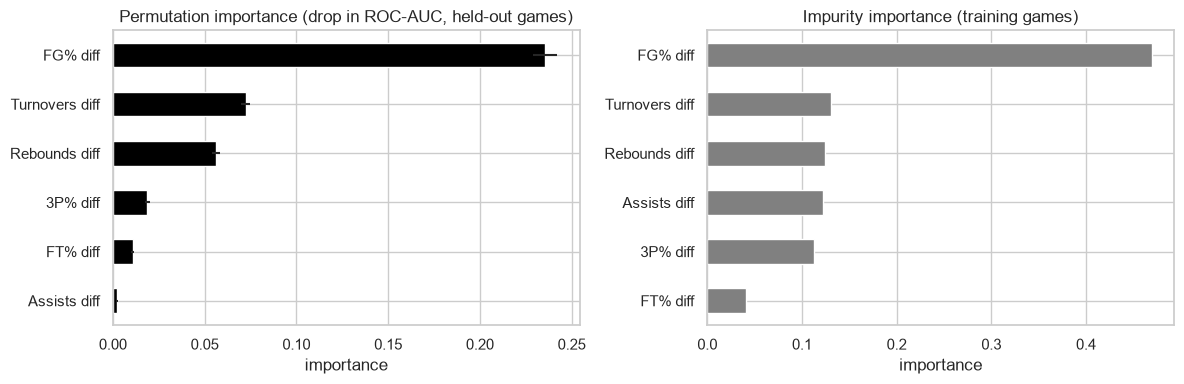

,permutation_importance,perm_std,impurity_importance
FG_PCT_diff,0.2356,0.0066,0.4695
TOV_diff,0.0723,0.0026,0.1308
REB_diff,0.0561,0.0022,0.1241
FG3_PCT_diff,0.0187,0.0014,0.1131
FT_PCT_diff,0.0108,0.0008,0.0403
AST_diff,0.0024,0.0006,0.1222


In [12]:
X_tr, X_te, y_tr, y_te = train_test_split(
    complete[ALL_FEATURES], complete[TARGET], test_size=0.2, stratify=complete[TARGET], random_state=RANDOM_STATE
)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr)

print(f"Held-out accuracy: {accuracy_score(y_te, rf.predict(X_te)):.3f}  "
      f"(always-predict-home baseline: {max(y_te.mean(), 1 - y_te.mean()):.3f})")
print(f"Held-out ROC-AUC:  {roc_auc_score(y_te, rf.predict_proba(X_te)[:, 1]):.3f}")

impurity_imp = pd.Series(rf.feature_importances_, index=ALL_FEATURES)
perm = permutation_importance(rf, X_te, y_te, scoring="roc_auc", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=ALL_FEATURES)
perm_sd = pd.Series(perm.importances_std, index=ALL_FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
order = perm_imp.sort_values().index
perm_imp[order].rename(index=NICE).plot(kind="barh", xerr=perm_sd[order].values, color="black", ax=axes[0])
axes[0].set(title="Permutation importance (drop in ROC-AUC, held-out games)", xlabel="importance")
impurity_imp.sort_values().rename(index=NICE).plot(kind="barh", color="gray", ax=axes[1])
axes[1].set(title="Impurity importance (training games)", xlabel="importance")
plt.tight_layout()
plt.savefig(FIGURES / "rf_feature_importance.png", bbox_inches="tight", dpi=150)
plt.show()

pd.DataFrame({"permutation_importance": perm_imp, "perm_std": perm_sd, "impurity_importance": impurity_imp}).sort_values(
    "permutation_importance", ascending=False).round(4)

**Random forest results.** The forest classifies 89.7% of held-out games correctly (ROC-AUC 0.967), against 59.7% for always picking the home team, so its importances are meaningful.

- Permutation importance: FG% (0.236 drop in ROC-AUC) is by far the largest, then turnovers (0.072), rebounds (0.056), 3P% (0.019), FT% (0.011) and assists (0.002).
- Two features move sharply compared with correlation: **turnovers rise from 5th to 2nd** and **assists fall from 2nd to last**. Turnovers add information beyond the other statistics, while assists add almost nothing once FG% and the rest are known.
- The built-in impurity importance (right panel) is computed on the training games and still gives assists a 0.12 share, because it counts how often a feature is used for splits rather than how much held-out predictions depend on it. Permutation importance on held-out games is the more reliable measure.

### Method 3: Mutual information

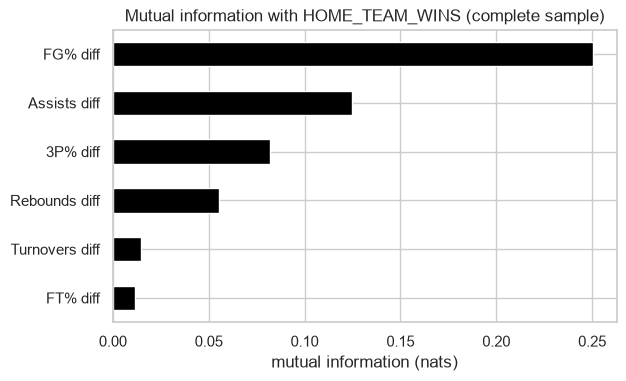

FG_PCT_diff     0.2503
AST_diff        0.1247
FG3_PCT_diff    0.0819
REB_diff        0.0555
TOV_diff        0.0144
FT_PCT_diff     0.0115
dtype: float64

In [13]:
mi = pd.Series(mutual_info_classif(complete[ALL_FEATURES], complete[TARGET], random_state=RANDOM_STATE), index=ALL_FEATURES)

ax = mi.sort_values().rename(index=NICE).plot(kind="barh", color="black", figsize=(6.5, 3.8))
ax.set(title="Mutual information with HOME_TEAM_WINS (complete sample)", xlabel="mutual information (nats)")
plt.savefig(FIGURES / "mutual_information.png", bbox_inches="tight", dpi=150)
plt.show()

mi.sort_values(ascending=False).round(4)

**Mutual information results.** The ranking matches correlation exactly: FG% (0.250), assists (0.125), 3P% (0.082), rebounds (0.056), turnovers (0.014), FT% (0.012). Mutual information also picks up non-linear relationships, so the match suggests the relationships here are close to monotonic. Like correlation, it scores each feature on its own, so assists again look strong.

### Method 4: Logistic regression standardised coefficients

Features are divided by their standard deviation (not re-centred), so each coefficient is the change in log-odds of a home win for a one-standard-deviation advantage in that statistic, holding the others fixed.
Not re-centring keeps the intercept meaningful: it is the log-odds of a home win when home and away are exactly equal on every statistic.
Confidence intervals come from 300 bootstrap resamples of the games. `C=1e9` makes the fit effectively unpenalised.

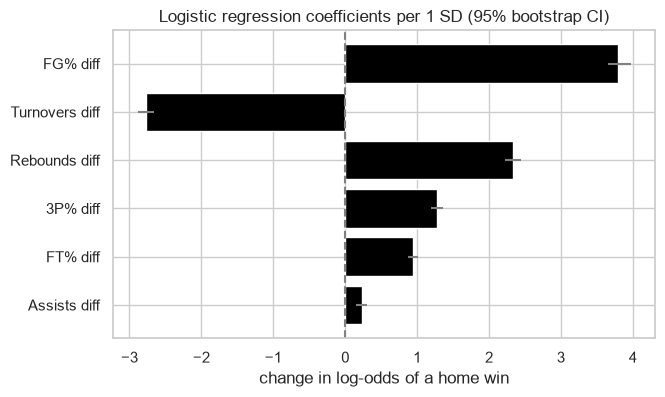

,coef_per_SD,ci_low,ci_high,odds_ratio_per_SD,ci_excludes_0
FG_PCT_diff,3.800,3.657,3.971,44.698,True
TOV_diff,-2.776,-2.887,-2.657,0.062,True
REB_diff,2.335,2.227,2.451,10.329,True
FG3_PCT_diff,1.271,1.194,1.364,3.565,True
FT_PCT_diff,0.946,0.878,1.018,2.576,True
AST_diff,0.229,0.146,0.307,1.257,True


In [14]:
def fit_lr(data, feats):
    scaler = StandardScaler(with_mean=False).fit(data[feats])
    lr = LogisticRegression(C=1e9, max_iter=2000).fit(scaler.transform(data[feats]), data[TARGET])
    return lr.intercept_[0], lr.coef_[0]


def bootstrap_lr(data, feats, n_boot=300, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    ints, coefs = [], []
    for _ in range(n_boot):
        s = data.iloc[rng.integers(0, len(data), len(data))]
        i, c = fit_lr(s, feats)
        ints.append(i)
        coefs.append(c)
    return np.array(ints), np.array(coefs)


intercept, coef = fit_lr(complete, ALL_FEATURES)
boot_int, boot_coef = bootstrap_lr(complete, ALL_FEATURES)

lr_tbl = pd.DataFrame({
    "coef_per_SD": coef,
    "ci_low": np.percentile(boot_coef, 2.5, axis=0),
    "ci_high": np.percentile(boot_coef, 97.5, axis=0),
    "odds_ratio_per_SD": np.exp(coef),
}, index=ALL_FEATURES)
lr_tbl["ci_excludes_0"] = (lr_tbl["ci_low"] > 0) | (lr_tbl["ci_high"] < 0)
lr_tbl = lr_tbl.sort_values("coef_per_SD", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
order = lr_tbl.index[::-1]
ax.barh([NICE[f] for f in order], lr_tbl.loc[order, "coef_per_SD"], color="black",
        xerr=[lr_tbl.loc[order, "coef_per_SD"] - lr_tbl.loc[order, "ci_low"],
              lr_tbl.loc[order, "ci_high"] - lr_tbl.loc[order, "coef_per_SD"]], ecolor="gray")
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="Logistic regression coefficients per 1 SD (95% bootstrap CI)", xlabel="change in log-odds of a home win")
plt.savefig(FIGURES / "logistic_standardized_coefficients.png", bbox_inches="tight", dpi=150)
plt.show()

lr_tbl.round(3)

**Logistic regression results** (all six features together; each coefficient is for a one-standard-deviation edge):

| Feature | Coefficient | Odds ratio | 95% bootstrap CI |
|---|---|---|---|
| FG% diff | +3.80 | 44.7 | 3.66 to 3.97 |
| Turnovers diff | -2.78 | 0.06 | -2.89 to -2.66 |
| Rebounds diff | +2.34 | 10.3 | 2.23 to 2.45 |
| 3P% diff | +1.27 | 3.6 | 1.19 to 1.36 |
| FT% diff | +0.95 | 2.6 | 0.88 to 1.02 |
| Assists diff | +0.23 | 1.3 | 0.15 to 0.31 |

- Every interval excludes 0, so each statistic has some independent effect, but assists is far smaller than the rest.
- The two methods that judge all features together (random forest permutation importance and logistic regression) agree on the complete order: FG%, turnovers, rebounds, 3P%, FT%, assists. The two one-feature-at-a-time methods (correlation and mutual information) agree with each other and put assists second.

### Check: drop one feature at a time

For each feature, refit the logistic regression without it and compare with the all-six model on the **same** five cross-validation folds.
`folds_hurt` counts the folds (out of 5) where removing the feature lowered accuracy.

In [15]:
def lr_cv(feats):
    model = make_pipeline(StandardScaler(), LogisticRegression(C=1e9, max_iter=2000))
    res = cross_validate(model, complete[feats], complete[TARGET], cv=cv, scoring=["accuracy", "roc_auc"])
    return res["test_accuracy"], res["test_roc_auc"]


base_acc, base_auc = lr_cv(ALL_FEATURES)
print(f"All six features: accuracy {base_acc.mean():.4f} (fold SD {base_acc.std():.4f}), ROC-AUC {base_auc.mean():.4f}")

rows = []
for f in ALL_FEATURES:
    acc, auc = lr_cv([g for g in ALL_FEATURES if g != f])
    rows.append({
        "dropped_feature": f,
        "accuracy_without": acc.mean(),
        "accuracy_loss": (base_acc - acc).mean(),
        "auc_loss": (base_auc - auc).mean(),
        "folds_hurt": int(((base_acc - acc) > 0).sum()),
    })
drop_one = pd.DataFrame(rows).set_index("dropped_feature").sort_values("accuracy_loss", ascending=False)
drop_one.round(4)

All six features: accuracy 0.9148 (fold SD 0.0067), ROC-AUC 0.9751


,accuracy_without,accuracy_loss,auc_loss,folds_hurt
dropped_feature,,,,
FG_PCT_diff,0.8238,0.0910,0.0711,5
TOV_diff,0.8401,0.0747,0.0522,5
REB_diff,0.8606,0.0542,0.0365,5
FG3_PCT_diff,0.8950,0.0198,0.0105,5
FT_PCT_diff,0.9029,0.0119,0.0070,5
AST_diff,0.9142,0.0005,0.0002,4


**Drop-one results.** The all-six model reaches 91.5% cross-validated accuracy (ROC-AUC 0.975). Removing one feature at a time:

- FG%: -9.1 points of accuracy. Turnovers: -7.5. Rebounds: -5.4. 3P%: -2.0. FT%: -1.2. Each of these hurts accuracy in all 5 folds.
- Assists: -0.05 points (ROC-AUC -0.0002), and in only 4 of 5 folds. Dropping assists costs essentially nothing.

## 4. Home-court advantage versus game statistics

The research question asks how much home-court advantage matters compared with shooting efficiency, rebounds, and assists. Two views, both on the `complete` sample:

**(a) How much do the statistics add over "home court alone"?** Home court alone can only say "the home team wins", which is right 59.7% of these games.
Each group of statistics is added to a logistic regression and scored with 5-fold cross-validation.

**(b) What is left of home-court advantage once the statistics are equal?** The intercept of the logistic regression above, converted to a probability.

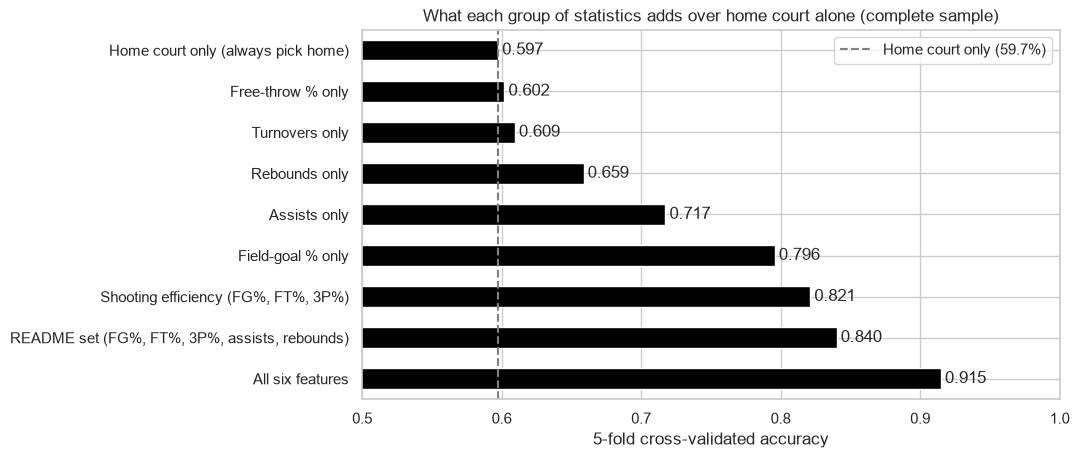

,n_features,cv_accuracy,cv_accuracy_sd,cv_roc_auc,gain_over_home_court
features,,,,,
Home court only (always pick home),0,0.597,0.000,0.500,0.000
Free-throw % only,1,0.602,0.003,0.585,0.005
Turnovers only,1,0.609,0.003,0.607,0.012
Rebounds only,1,0.659,0.005,0.696,0.061
Assists only,1,0.717,0.009,0.782,0.120
Field-goal % only,1,0.796,0.004,0.879,0.198
"Shooting efficiency (FG%, FT%, 3P%)",3,0.821,0.003,0.903,0.224
"README set (FG%, FT%, 3P%, assists, rebounds)",5,0.840,0.004,0.923,0.243
All six features,6,0.915,0.007,0.975,0.317


In [16]:
groups = {
    "Home court only (always pick home)": [],
    "Free-throw % only": ["FT_PCT_diff"],
    "Turnovers only": ["TOV_diff"],
    "Rebounds only": ["REB_diff"],
    "Assists only": ["AST_diff"],
    "Field-goal % only": ["FG_PCT_diff"],
    "Shooting efficiency (FG%, FT%, 3P%)": ["FG_PCT_diff", "FT_PCT_diff", "FG3_PCT_diff"],
    "README set (FG%, FT%, 3P%, assists, rebounds)": ["FG_PCT_diff", "FT_PCT_diff", "FG3_PCT_diff", "AST_diff", "REB_diff"],
    "All six features": ALL_FEATURES,
}

rows = []
for name, feats in groups.items():
    if feats:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=1e9, max_iter=2000))
        X = complete[feats]
    else:
        model = DummyClassifier(strategy="most_frequent")
        X = complete[[ALL_FEATURES[0]]]
    res = cross_validate(model, X, complete[TARGET], cv=cv, scoring=["accuracy", "roc_auc"])
    rows.append({"features": name, "n_features": len(feats),
                 "cv_accuracy": res["test_accuracy"].mean(), "cv_accuracy_sd": res["test_accuracy"].std(),
                 "cv_roc_auc": res["test_roc_auc"].mean()})

compare = pd.DataFrame(rows).set_index("features")
baseline_acc = compare.loc["Home court only (always pick home)", "cv_accuracy"]
compare["gain_over_home_court"] = compare["cv_accuracy"] - baseline_acc

fig, ax = plt.subplots(figsize=(9, 4.8))
compare["cv_accuracy"].iloc[::-1].plot(kind="barh", color="black", ax=ax, label="_nolegend_")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.axvline(baseline_acc, color="gray", linestyle="--", label=f"Home court only ({baseline_acc:.1%})")
ax.set(xlim=(0.5, 1.0), xlabel="5-fold cross-validated accuracy", ylabel="",
       title="What each group of statistics adds over home court alone (complete sample)")
ax.legend(loc="upper right")
plt.savefig(FIGURES / "home_court_vs_statistics.png", bbox_inches="tight", dpi=150)
plt.show()

compare.round(3)

In [17]:
p_equal = 1 / (1 + np.exp(-intercept))
p_equal_boot = 1 / (1 + np.exp(-boot_int))
raw_rate = complete[TARGET].mean()
print(f"Home win rate in the complete sample (no statistics used):                    {raw_rate:.1%}")
print(f"Home win probability when home and away are equal on all six statistics:      {p_equal:.1%}")
print(f"  95% bootstrap CI: {np.percentile(p_equal_boot, 2.5):.1%} to {np.percentile(p_equal_boot, 97.5):.1%}")
print(f"Points of home advantage above 50%: {100 * (raw_rate - 0.5):.1f} overall, {100 * (p_equal - 0.5):.1f} at equal statistics")

Home win rate in the complete sample (no statistics used):                    59.7%
Home win probability when home and away are equal on all six statistics:      53.9%
  95% bootstrap CI: 52.5% to 55.6%
Points of home advantage above 50%: 9.7 overall, 3.9 at equal statistics


**(a) What the statistics add.** Always picking the home team is right 59.7% of the time in these games.

| Features | CV accuracy | Gain over home court |
|---|---|---|
| Free-throw % only | 60.2% | +0.5 |
| Turnovers only | 60.9% | +1.2 |
| Rebounds only | 65.9% | +6.1 |
| Assists only | 71.7% | +12.0 |
| Field-goal % only | 79.6% | +19.8 |
| Shooting efficiency (FG%, FT%, 3P%) | 82.1% | +22.4 |
| README set (adds assists and rebounds) | 84.0% | +24.3 |
| All six features | 91.5% | +31.7 |

Shooting efficiency tells you the most about who won: FG% alone adds 19.8 points, more than assists (12.0) or rebounds (6.1) alone. Assists look useful alone but add almost nothing once the other statistics are present (see the drop-one check).

**(b) What is left of home-court advantage at equal statistics.** When the home and away teams are equal on all six statistics, the model still gives the home team a 53.9% chance of winning (95% CI 52.5% to 55.6%). Of the 9.7-point home edge in these games, about 3.9 points remain at equal statistics. The other roughly 5.8 points (about 60%) show up through home teams posting better statistics in the same game, such as better shooting, more rebounds and fewer turnovers.

**Answer to the research question.** Home-court advantage is real but modest: about 10 points above a coin flip, and about 4 points once the six game statistics are equal. It is small next to what shooting efficiency, turnovers and rebounds in the game reveal about who won. Two cautions: the six statistics leave out things like shot attempts and free-throw attempts, so the remaining 3.9 points mean "not explained by these six", not necessarily "pure home court"; and these are same-game statistics, so this describes association, not cause.

## 5. Combining the methods

Each of the four methods ranks the six features (1 = strongest). The last column is the average rank.

In [18]:
rank_input = pd.DataFrame({
    "|correlation|": corr_target.abs(),
    "RF permutation importance": perm_imp,
    "mutual information": mi,
    "|LR coefficient|": lr_tbl["coef_per_SD"].abs(),
}).loc[ALL_FEATURES]

ranks = rank_input.rank(ascending=False).astype(int)
ranks["mean_rank"] = ranks.mean(axis=1)
ranks = ranks.sort_values("mean_rank")

display(rank_input.loc[ranks.index].round(4))
display(ranks.rename(index=NICE))

,|correlation|,RF permutation importance,mutual information,|LR coefficient|
FG_PCT_diff,0.6240,0.2356,0.2503,3.7999
FG3_PCT_diff,0.3857,0.0187,0.0819,1.2710
REB_diff,0.3343,0.0561,0.0555,2.3350
TOV_diff,0.1855,0.0723,0.0144,2.7762
AST_diff,0.4760,0.0024,0.1247,0.2288
FT_PCT_diff,0.1452,0.0108,0.0115,0.9460


,|correlation|,RF permutation importance,mutual information,|LR coefficient|,mean_rank
FG% diff,1,1,1,1,1.0
3P% diff,3,4,3,4,3.5
Rebounds diff,4,3,4,3,3.5
Turnovers diff,5,2,5,2,3.5
Assists diff,2,6,2,6,4.0
FT% diff,6,5,6,5,5.5


**Reading the ranking**

- FG% is first on all four methods.
- The other features reorder depending on whether the method judges them one at a time (correlation, mutual information) or together (random forest, logistic regression). Assists are 2nd on the first pair and last on the second; turnovers are 5th and 2nd. The average ranks for 3P%, rebounds and turnovers (all 3.5) and assists (4.0) are too close to separate those four, which is why the drop-one check decides the final set.
- FT% ranks 5th or 6th on every method, but removing it still lowers cross-validated accuracy in every fold (-1.2 points), so it stays.

## Final feature set

**Keep (5):** `FG_PCT_diff`, `TOV_diff`, `REB_diff`, `FG3_PCT_diff`, `FT_PCT_diff`  
**Drop (1):** `AST_diff`

**Rule:** a feature is kept if removing it lowers cross-validated accuracy in all five folds (drop-one check), which is also what the four methods suggest when read together. The code cell below applies the same rule to the drop-one table and checks it matches this list.

| Feature | Decision | Why |
|---|---|---|
| `FG_PCT_diff` | **Keep** | First on all four methods (correlation 0.62). Removing it costs 9.1 points of accuracy, the most of any feature. The core shooting-efficiency measure in the research question. |
| `TOV_diff` | **Keep** | Weak on its own (correlation -0.19) but 2nd on both joint methods, and removing it costs 7.5 points. It carries information that shooting and rebounding do not. It is not in the README feature list; it was added in Notebook 2. |
| `REB_diff` | **Keep** | Correlation 0.33, 3rd on both joint methods, removing it costs 5.4 points. Named in the research question. |
| `FG3_PCT_diff` | **Keep** | Correlation 0.39, 4th on both joint methods, removing it costs 2.0 points. |
| `FT_PCT_diff` | **Keep** | The weakest signal (correlation 0.15, Cohen's d 0.30), but removing it lowers accuracy in every fold (-1.2 points). Named in the research question. |
| `AST_diff` | **Drop** | Strong on its own (correlation 0.48, 2nd on correlation and mutual information) because assists mostly accompany made field goals (r = 0.59 with FG%). With the others in the model it has the smallest coefficient (0.23), near-zero permutation importance (0.002), and removing it changes accuracy by only -0.05 points (4 of 5 folds). |

**On assists:** dropping the feature does not mean assists are unrelated to winning. The research question asks about them, and the analysis above answers it: assists alone classify 71.7% of games, but almost all of that overlaps with field-goal shooting. If the group prefers to keep `AST_diff` for reporting, a logistic regression loses or gains less than 0.1 points of accuracy either way.

In [19]:
FINAL_FEATURES = ["FG_PCT_diff", "TOV_diff", "REB_diff", "FG3_PCT_diff", "FT_PCT_diff"]
DROPPED_FEATURES = ["AST_diff"]

# The rule from the text above, applied to the drop-one table: keep if removal hurts all 5 folds.
rule_keep = [f for f in ALL_FEATURES if drop_one.loc[f, "folds_hurt"] == 5]
assert sorted(rule_keep) == sorted(FINAL_FEATURES), rule_keep
assert sorted(FINAL_FEATURES + DROPPED_FEATURES) == sorted(ALL_FEATURES)

# Rows to model on: seasons with real statistics (<= 2015) and no missing selected feature.
MODELING_ROWS = df[df["season"] <= 2015].dropna(subset=FINAL_FEATURES)

print("Final features:", FINAL_FEATURES)
print(f"Modeling rows: {len(MODELING_ROWS):,} games, seasons {MODELING_ROWS['season'].min()} to "
      f"{MODELING_ROWS['season'].max()} ({MODELING_ROWS['season'].nunique()} seasons)")
print(f"Home win rate in those rows: {MODELING_ROWS[TARGET].mean():.1%}")
MODELING_ROWS[FINAL_FEATURES].describe().T.round(3)

Final features: ['FG_PCT_diff', 'TOV_diff', 'REB_diff', 'FG3_PCT_diff', 'FT_PCT_diff']
Modeling rows: 16,816 games, seasons 2000 to 2015 (14 seasons)
Home win rate in those rows: 59.7%


,count,mean,std,min,25%,50%,75%,max
FG_PCT_diff,16816.0,0.012,0.079,-0.307,-0.041,0.012,0.066,0.342
TOV_diff,16816.0,-0.376,5.032,-21.000,-4.000,0.000,3.000,21.000
REB_diff,16816.0,1.454,8.868,-31.000,-4.000,1.000,7.000,37.000
FG3_PCT_diff,16816.0,0.006,0.178,-0.824,-0.111,0.004,0.122,0.692
FT_PCT_diff,16816.0,0.004,0.140,-0.574,-0.087,0.001,0.097,0.624


## Handoff to Notebook 4 (modeling)

1. **Features:** use `FINAL_FEATURES` above (5 features). `AST_diff` is excluded.
2. **Rows:** keep only games with `season <= 2015` and no missing value in the final features. That is **16,816 games from 14 seasons** (2000–2015, no 2003, no 2013), exactly the `MODELING_ROWS` selection above. Do not use 2016–2025 rows: FT% there is placeholder zeros and FG% is unreliable (see the data check).
3. **Notebook 4 needs a small update.** Its scaffold takes every column ending in `_diff` from every row. That would include `AST_diff`, include the 2016–2025 rows, and fail on missing values. The cell that loads the data should instead use `FINAL_FEATURES` and the `MODELING_ROWS` filter.
4. **Baseline to beat:** always predicting a home win is right 59.7% of the time on these games (60.8% across all 31,230). Reference results from this notebook: logistic regression reaches about 91.5% cross-validated accuracy (ROC-AUC 0.975) with all six features and about 91.4% with the final five; the random forest used for importance reaches 89.7% accuracy (ROC-AUC 0.967) on a held-out 20% with `min_samples_leaf=20` and no tuning.
5. **Scaling:** logistic regression and kNN need standardised features (`StandardScaler` inside the pipeline, fitted on the training data only). Tree models do not.
6. **Prediction versus explanation:** these are same-game statistics, so a model using them classifies completed games rather than forecasting games before tip-off (as Notebook 2 also notes). The report should describe results that way. Notebook 2 also suggests a chronological split to test on later seasons; within 2000–2015 that would mean training on earlier seasons and testing on the last few.
7. **Figures** produced by this notebook are in `reports/figures/`: `home_win_rate_by_season.png`, `feature_availability_by_season.png`, `data_quality_2016_2025.png`, `feature_distributions_by_outcome.png`, `feature_correlation_heatmap.png`, `rf_feature_importance.png`, `mutual_information.png`, `logistic_standardized_coefficients.png`, `home_court_vs_statistics.png`.
8. **Open issue for Notebook 2 (Tony):** the 2016–2025 `FT_PCT_diff` zeros and unreliable `FG_PCT_diff` values are still in `games_processed.csv`; see the data check near the top.